## Семинар 9: Transofrmer. Attention

На этом семинаре мы продолжим рассмотрение архитектуры Transformer и механизма Attention, а также познакомимся с полезным ресурсом HuggingFace и его библиотекой.


--------

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import Linear, Module, LayerNorm, Dropout, ReLU, Embedding, ModuleList, CrossEntropyLoss
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
import os
import random
import numpy as np
import re
import math
from tqdm.auto import tqdm

import matplotlib
matplotlib.rcParams['figure.figsize'] = (10, 6)

import matplotlib.pyplot as plt


def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything()
device = torch.device('cuda')

### 1. Attention

Attention (внимание) — это механизм, используемый в нейронных сетях, который позволяет модели фокусироваться на определённых частях входных данных при генерации выходных данных.

Основная идея attention заключается в том, чтобы взвешивать вклад различных частей входной последовательности при формировании каждого элемента выходной последовательности. Это позволяет модели более эффективно обрабатывать длинные последовательности и учитывать контекст, что особенно важно в задачах, где порядок и взаимосвязь элементов имеют значение.

В механизме attention ключевую роль играют такие термины, как query (запрос), key (ключ) и value (значение). Эти концепции помогают модели определять, на какие части входной последовательности следует обратить внимание при обработке каждого элемента. Вот как они работают:

1. Query (запрос): Это вектор, который представляет текущий элемент последовательности, для которого мы хотим определить, на какие другие элементы следует обратить внимание. По сути, query используется для "запроса" информации из других частей последовательности.

2. Key (ключ): Это вектор, который представляет каждый элемент последовательности и используется для сопоставления с query. Keys помогают определить, насколько важен каждый элемент последовательности для текущего элемента, представленного query.

3. Value (значение): Это вектор, который содержит фактическую информацию, которую мы хотим извлечь из каждого элемента последовательности. Values взвешиваются в соответствии с результатами сопоставления query и key, чтобы сформировать итоговое представление.

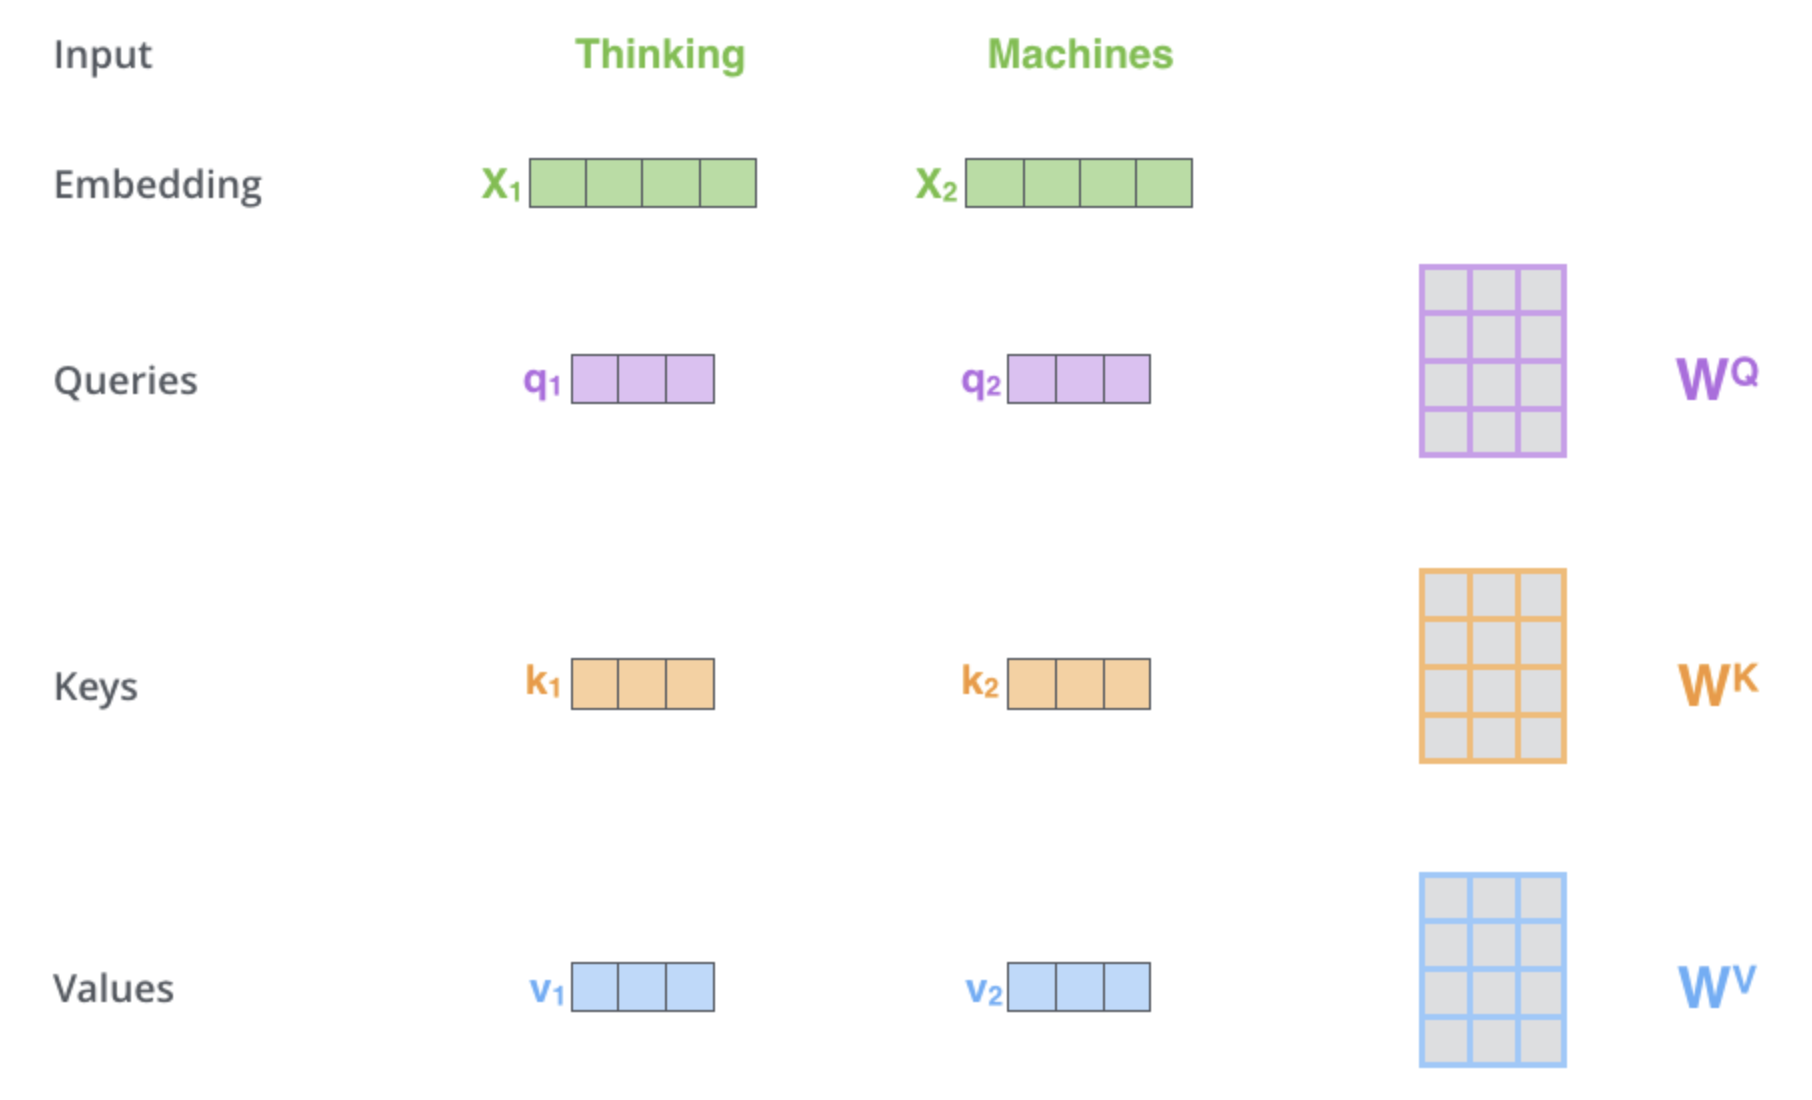

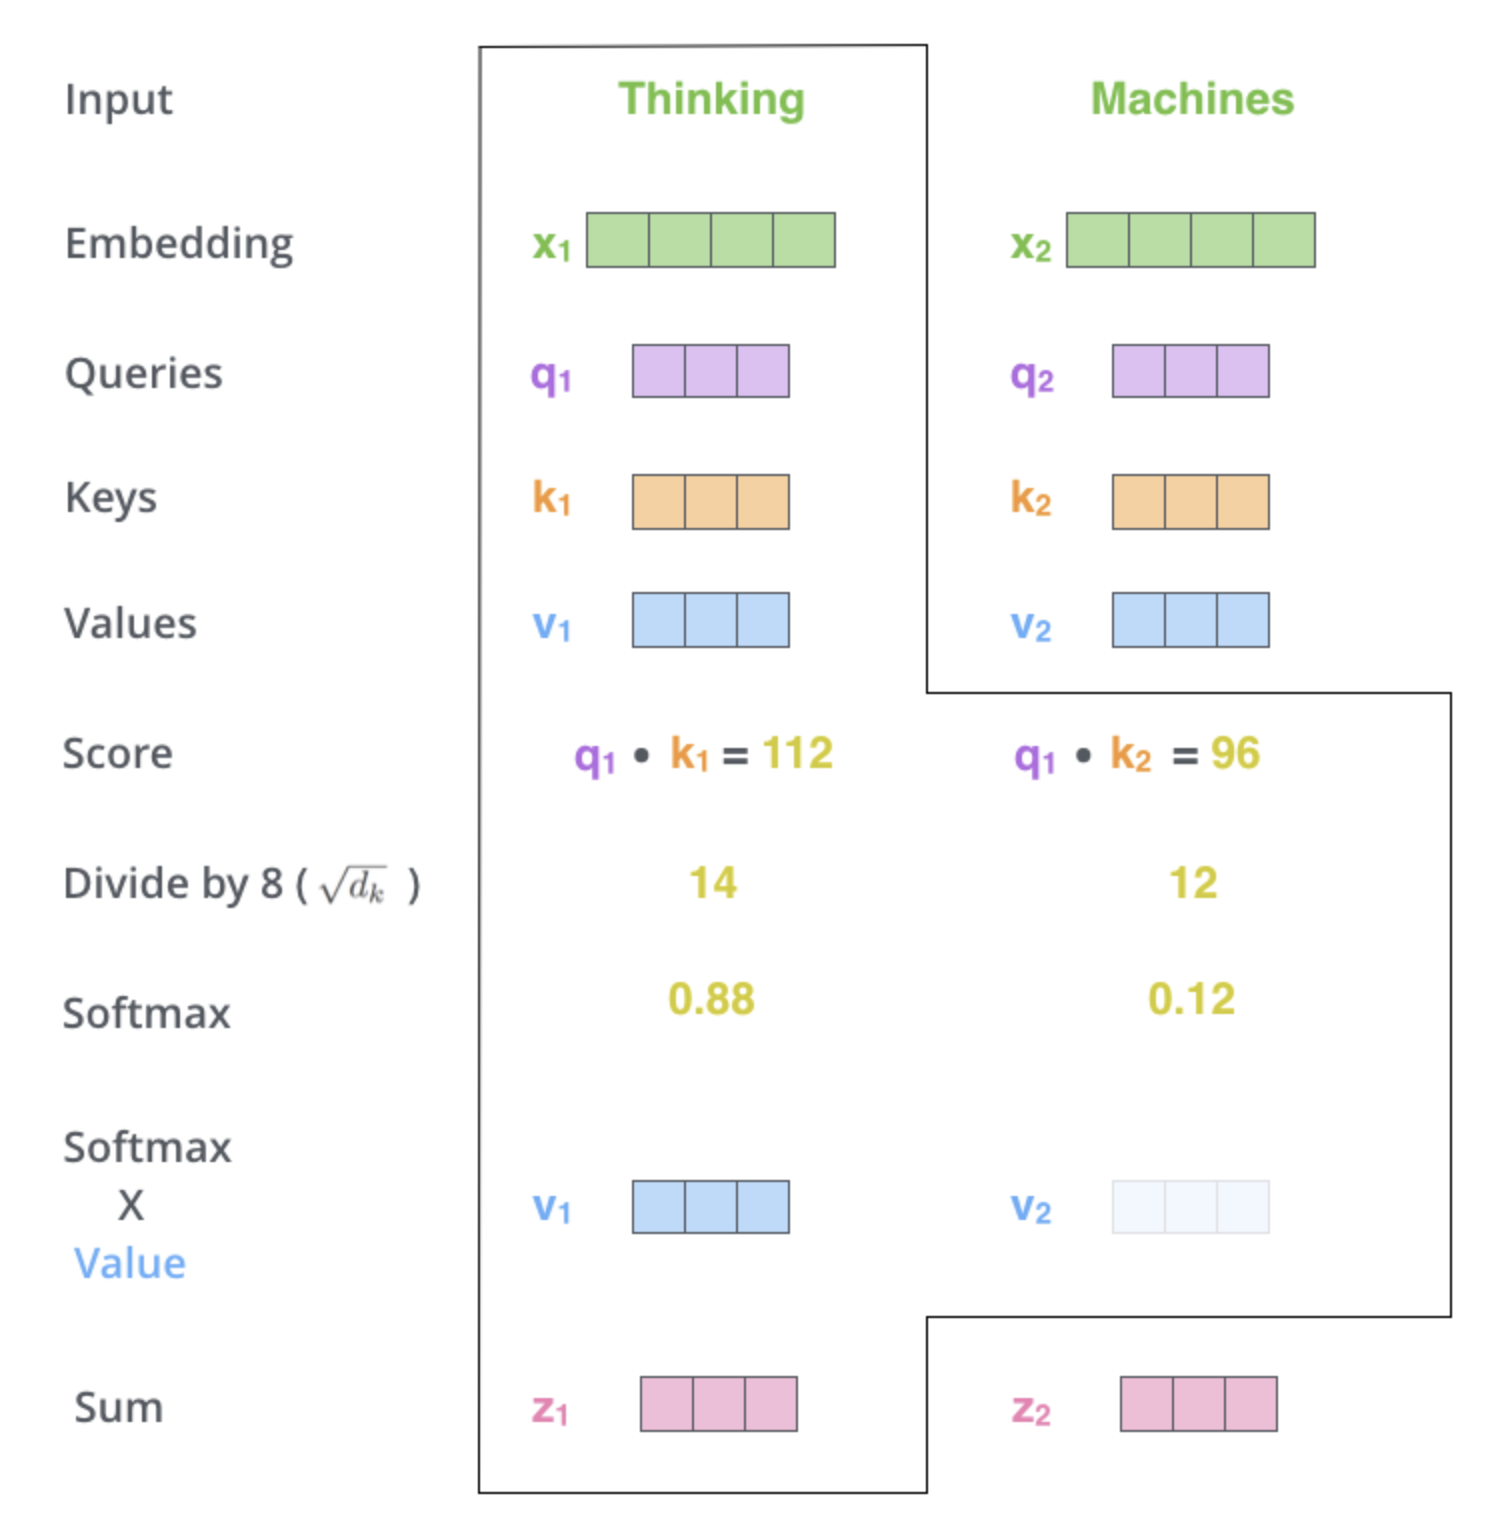

Attention в матричной форме:

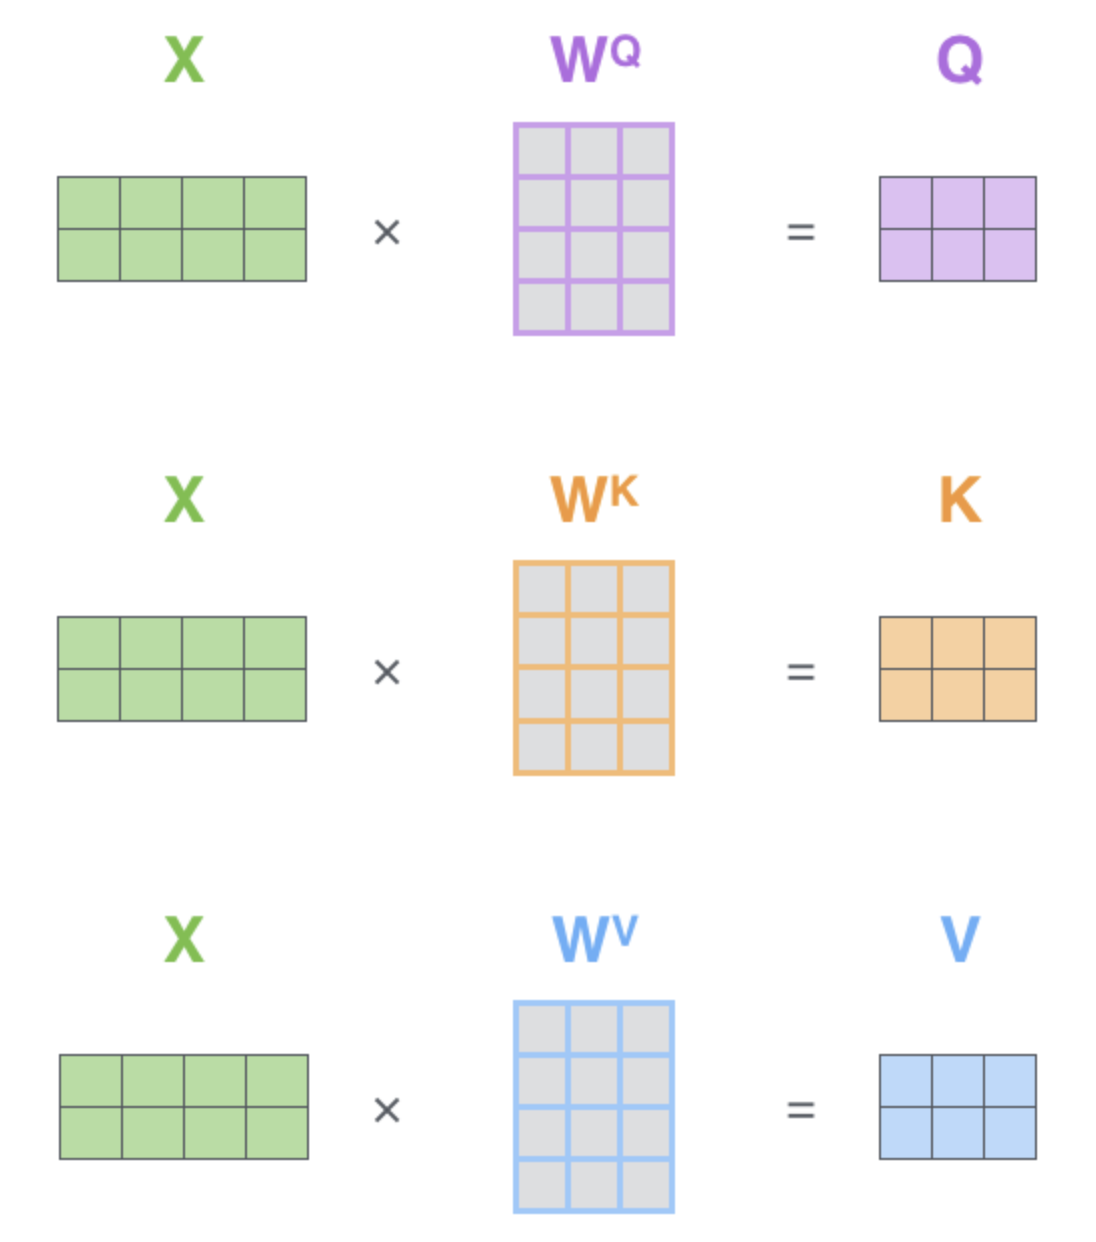

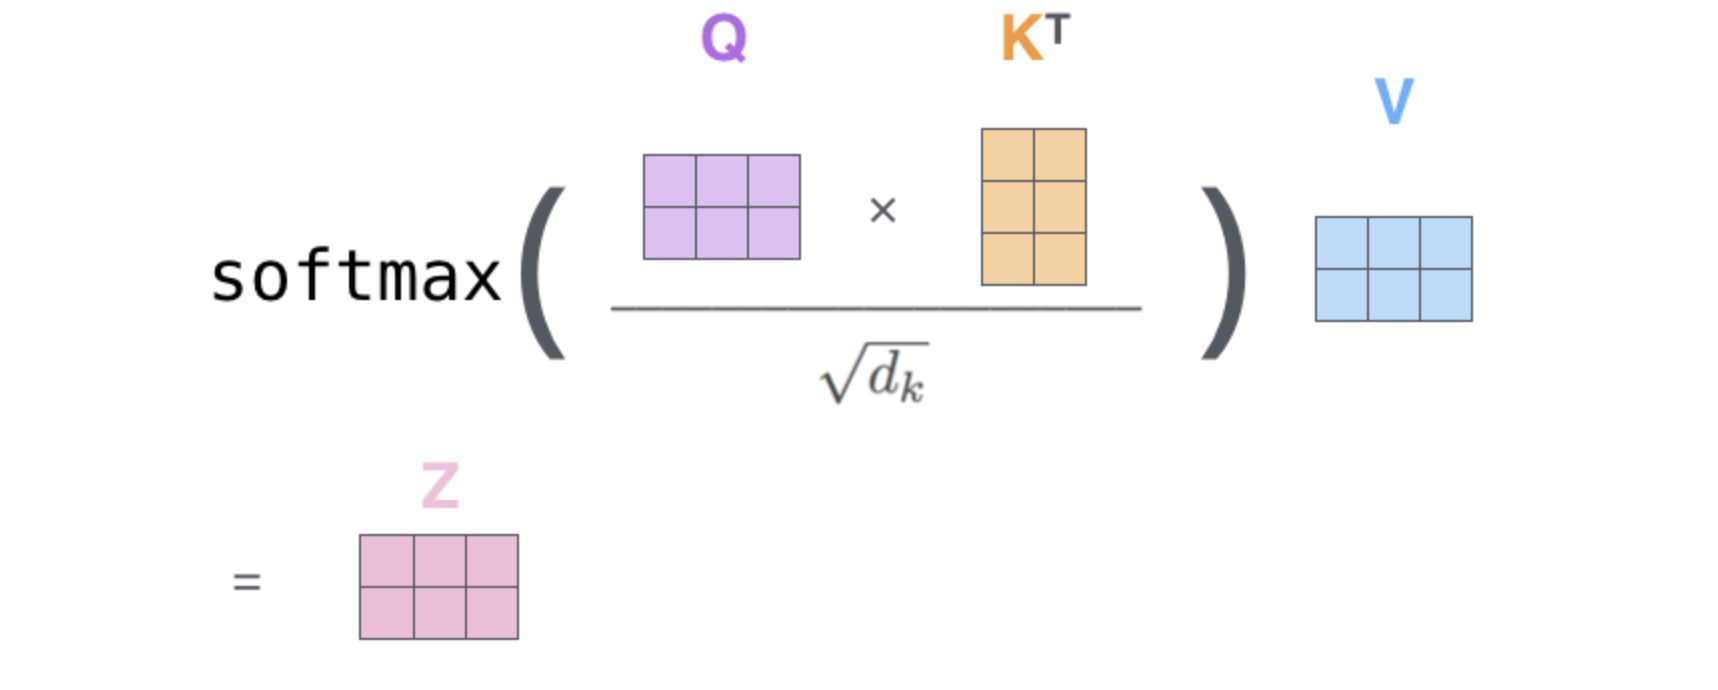

Процесс attention можно описать следующим образом:

- Для каждого элемента последовательности вычисляется query, key и value.
- Для каждого query вычисляется скалярное произведение с каждым key, чтобы определить степень "внимания" или важности каждого элемента.
- Эти скалярные произведения нормализуются (обычно с помощью softmax), чтобы получить веса внимания.
- Эти веса используются для взвешивания соответствующих value, и взвешенные значения суммируются, чтобы получить итоговое представление для текущего элемента.

### Attention

In [6]:
import math
import torch
import torch.nn.functional as F

def attention(queries, keys, values, Q, K, V, mask=None):
    # Входные тензоры имеют размерность: (batch_size, length, emb_size)
    # Маска имеет размерность: (batch_size, q_length, k_length)
    # Q, K и V — линейные слои (Projection layers): emb_size -> emb_size

    # Получаем размерность эмбеддинга (d_k) из последнего измерения тензора
    emb_size = queries.size(-1)

    # Линейное проецирование входных векторов в пространства Запросов (Queries), Ключей (Keys) и Значений (Values)
    # Размерности остаются прежними: (batch_size, length, emb_size)
    queries = Q(queries)
    keys = K(keys)
    values = V(values)

    # 1. Скалярное произведение Queries и Keys с масштабированием (Scaled Dot-Product)
    # Транспонируем последние две размерности keys: (batch_size, emb_size, k_length)
    # Результат матричного умножения: (batch_size, q_length, k_length)
    # Деление на sqrt(emb_size) стабилизирует градиенты при больших размерностях
    query_key_connection = torch.matmul(queries, keys.transpose(-1, -2)) / math.sqrt(emb_size)

    # 2. Применение маски (если она передана)
    # Заменяем элементы, где mask == 0, на минус бесконечность (-inf)
    # Это нужно, чтобы после Softmax эти связи занулились (например, для маскирования будущих токенов в декодере)
    if mask is not None:
        query_key_connection = query_key_connection.masked_fill(mask == 0, -torch.inf)

    # 3. Нормализация весов внимания (Softmax)
    # Применяется по последней оси (-1), превращая логиты в вероятностное распределение
    # Размерность: (batch_size, q_length, k_length)
    normalized_query_key = F.softmax(query_key_connection, -1)

    # 4. Взвешенное суммирование значений (Values)
    # Умножаем матрицу весов внимания на матрицу значений Values
    # Размерность результата: (batch_size, q_length, emb_size)
    reweighted_values = torch.matmul(normalized_query_key, values)

    # Возвращаем обновленные представления векторов и саму матрицу весов внимания (для визуализации)
    return reweighted_values


In [7]:
queries = torch.randn((2, 5, 32))
keys = torch.randn((2, 5, 32))
values = torch.randn((2, 5, 32))

Q = Linear(32, 32)
K = Linear(32, 32)
V = Linear(32, 32)
proj = Linear(32, 32)

mask = torch.ones((2, 5, 5))

In [8]:
attention(queries, keys, values, Q, K, V, mask).shape

torch.Size([2, 5, 32])

Где используется Attention?

в Transformer!

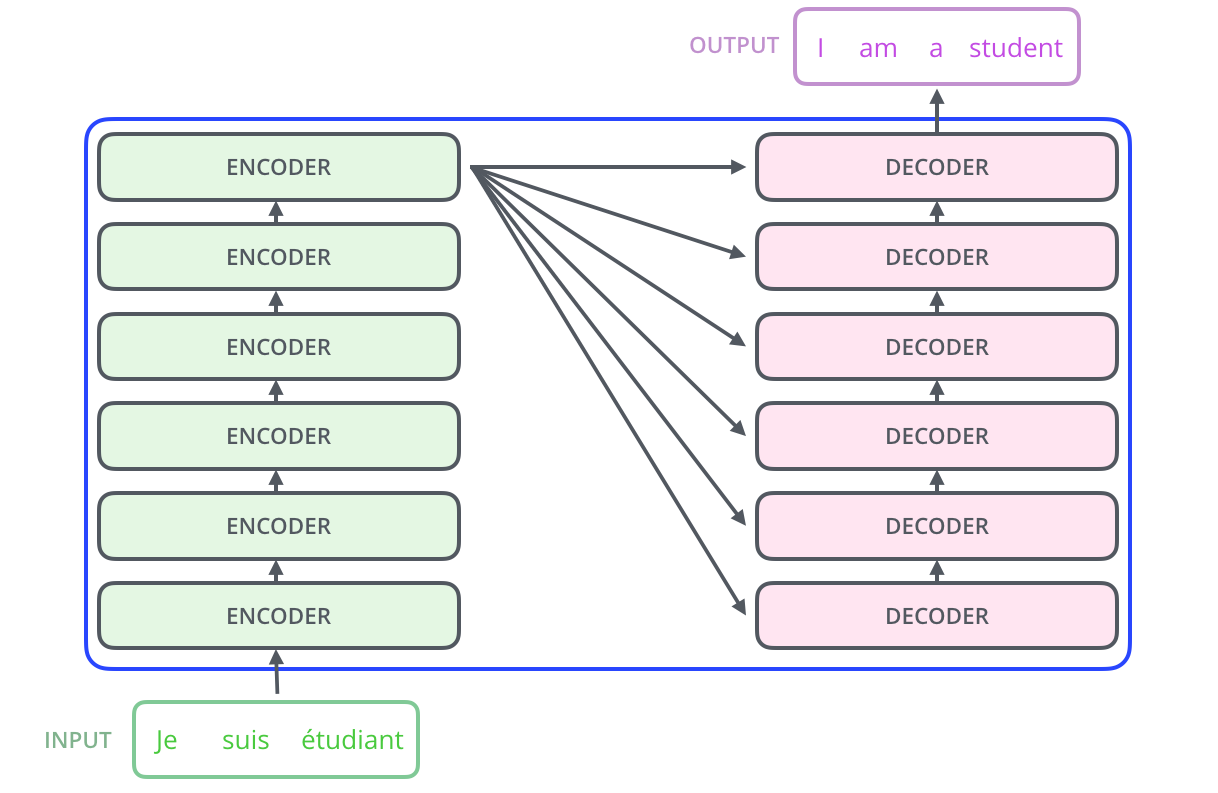

Трансформер состоит последовательности Encoder и Decoder блоков, в каждом из которых используется механизм Attention

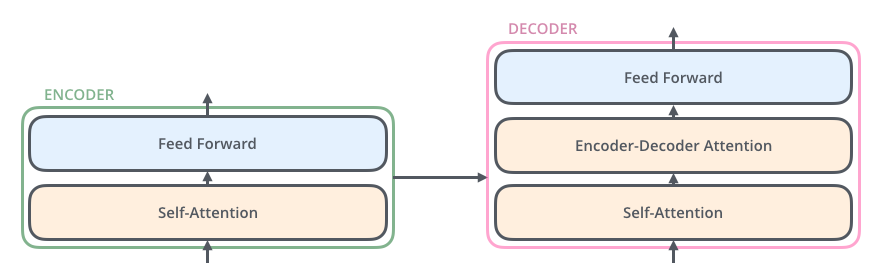

In [ ]:
from IPython.display import Image
Image(url='https://jalammar.github.io/images/t/transformer_decoding_1.gif')

In [ ]:
from IPython.display import Image
Image(url='https://jalammar.github.io/images/t/transformer_decoding_2.gif')

Один из лучших источников, где объясняется как работает механизм Attention и Transformer целиком это https://jalammar.github.io/illustrated-transformer/

### 2. HuggingFace

[Hugging Face](https://huggingface.co/) — это компания и сообщество, которые специализируются на разработке инструментов и библиотек для машинного обучения. Они стали особенно известны благодаря своей библиотеке Transformers, которая предоставляет доступ к множеству предобученных моделей для различных задач NLP, таких как классификация текста, генерация текста, машинный перевод и многое другое.

Основные компоненты и продукты Hugging Face включают:

1. Transformers: Это одна из самых популярных библиотек для работы с моделями трансформеров, такими как BERT, GPT, T5 и другими. Она позволяет легко загружать предобученные модели и адаптировать их для различных задач.

2. Datasets: Библиотека, которая предоставляет доступ к множеству наборов данных для обучения и тестирования моделей машинного обучения. Она упрощает процесс загрузки, предварительной обработки и использования данных.

3. Tokenizers: Библиотека для токенизации текста, которая поддерживает различные методы токенизации, используемые в современных моделях NLP.

4. Model Hub: Онлайн-платформа, где пользователи могут делиться своими предобученными моделями и находить модели, созданные другими. Это позволяет исследователям и разработчикам быстро находить и использовать модели для своих задач.

5. Hugging Face Spaces: Платформа для развертывания и демонстрации моделей машинного обучения с помощью простых веб-интерфейсов.



In [1]:
# !pip install --upgrade datasets huggingface_hub transformers
# !pip install -U "huggingface_hub>=0.28.0" "datasets>=3.0.0" "transformers>=4.45.0"
!pip install -q datasets==3.6.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 10.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


#### 2.1 datasets

Библиотека предоставляет доступ к тысячам наборов данных для различных задач, таких как классификация текста, машинный перевод, извлечение информации и многое другое. Эти наборы данных можно легко загружать и использовать в своих проектах.

Сегодня мы будем рассматривать работу с платформой HF на примере классической дискриминативной задачи NLP - классификации токенов. Эта общая задача охватывает любую проблему обработки последовательностей слов, которую можно сформулировать как "присвоение метки каждому токену в предложении", например:

* **Распознавание именованных сущностей (Named entity recognition - NER)**: Поиск сущностей (например, лиц, мест или организаций) в предложении. Это можно сформулировать как приписывание метки каждому токену, имея один класс для сущности и один класс для "нет сущности".
* **Морфологическая разметка (Part-of-speech tagging - POS)**: Пометить каждое слово в предложении как соответствующее определенной части речи (например, существительное, глагол, прилагательное и т. д.).
* **Выделение токенов (Chunking)**: Поиск токенов, принадлежащих одной и той же сущности. Эта задача (которая может быть объединена с POS или NER) может быть сформулирована как присвоение одной метки (обычно B - beginning) всем токенам, которые находятся в начале фрагмента текста, другой метки (обычно I - inside) - токенам, которые находятся внутри фрагмента текста, и третьей метки (обычно O - outside) - токенам, которые не принадлежат ни к одному фрагменту.

Итак, нам нужен набор данных, подходящий для классификации токенов. В этом разделе мы будем использовать набор данных [WikiANN](https://huggingface.co/datasets/wikiann), который содержит статьи из Википедии, размеченные на задачу NER на почти 170 параллельных языках. Мы возьмём часть на русском языке.

Для загрузки датасета мы используем метод `load_dataset()` из библиотеки 🤗 Datasets:

In [2]:
from huggingface_hub import login

login(token="hf_ВАШ_ТОКЕН")

In [3]:
from datasets import load_dataset

raw_datasets = load_dataset("unimelb-nlp/wikiann", "ru")

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Давайте посмотрим внимательнее на выгруженный объект:

In [4]:
raw_datasets

DatasetDict({
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 10000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 20000
    })
})

Можно заметить, что датасет содержит метки для задач, о которых мы говорили ранее: NER и chunking. Существенным отличием от других датасетов является то, что входные тексты представлены не как предложения или документы, а как списки слов (первый столбец называется tokens, но он содержит слова в том смысле, что это предварительно токенизированные входные данные, которые еще должны пройти через токенизатор для токенизации по подсловам).

Давайте посмотрим на первый элемент обучающего набора:

In [5]:
raw_datasets["train"][0]["tokens"]

['Илизаров', ',', 'Гавриил', 'Абрамович']

Поскольку мы хотим выполнить распознавание именованных сущностей, посмотрим на разметку:

In [6]:
raw_datasets["train"][0]["ner_tags"]

[1, 2, 2, 2]

Это лейблы в виде целых чисел, готовые для обучения, но они не всегда полезны, когда мы хотим проанализировать данные. Как и в случае с классификацией текста, мы можем получить доступ к соответствию между этими целыми числами и названиями лейблов, посмотрев на атрибут [`features`](https://huggingface.co/docs/datasets/v2.19.0/en/package_reference/main_classes#datasets.Features) нашего датасета:


In [7]:
raw_datasets["train"].features

{'tokens': Sequence(feature=Value(dtype='string', id=None), length=-1, id=None),
 'ner_tags': Sequence(feature=ClassLabel(names=['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC'], id=None), length=-1, id=None),
 'langs': Sequence(feature=Value(dtype='string', id=None), length=-1, id=None),
 'spans': Sequence(feature=Value(dtype='string', id=None), length=-1, id=None)}

In [8]:
ner_feature = raw_datasets["train"].features["ner_tags"]
ner_feature

Sequence(feature=ClassLabel(names=['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC'], id=None), length=-1, id=None)

Таким образом, этот столбец содержит элементы, которые являются последовательностями [`ClassLabel`](https://huggingface.co/docs/datasets/v2.19.0/en/package_reference/main_classes#datasets.ClassLabel). Тип элементов последовательности указан в атрибуте `feature` объекта `ner_feature`, и мы можем получить доступ к списку имен, посмотрев на атрибут `names` этого `feature`:

In [9]:
label_names = ner_feature.feature.names
label_names

['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']

* `O` означает, что слово не соответствует какой-либо сущности.
* `B-PER/I-PER` означает, что слово соответствует началу/находится внутри сущности *person*.
* `B-ORG/I-ORG` означает, что слово соответствует началу/находится внутри сущности *organization*.
* `B-LOC/I-LOC` означает, что слово соответствует началу/находится внутри сущности *location*.

Посмотрим на пример из выборки с декодированной из целых чисел разметкой сущностей:

In [10]:
words = raw_datasets["train"][0]["tokens"]
labels = raw_datasets["train"][0]["ner_tags"]
line1 = ""
line2 = ""
for word, label in zip(words, labels):
    full_label = label_names[label]
    max_length = max(len(word), len(full_label))
    line1 += word + " " * (max_length - len(word) + 1)
    line2 += full_label + " " * (max_length - len(full_label) + 1)

print(line1)
print(line2)

Илизаров ,     Гавриил Абрамович 
B-PER    I-PER I-PER   I-PER     


В качестве примера смешивания меток `B-` и `I-` можно посмотреть на сущность, состоящую из нескольких слов. Первому слову присваивается метка `B-`, всем последующим - `I-`.

In [11]:
words = raw_datasets["train"][3]["tokens"]
labels = raw_datasets["train"][3]["ner_tags"]
line1 = ""
line2 = ""
for word, label in zip(words, labels):
    full_label = label_names[label]
    max_length = max(len(word), len(full_label))
    line1 += word + " " * (max_length - len(word) + 1)
    line2 += full_label + " " * (max_length - len(full_label) + 1)

print(line1)
print(line2)

Стадион имени С.    Дарюса и     С.    Гиренаса 
B-LOC   I-LOC I-LOC I-LOC  I-LOC I-LOC I-LOC    


#### 2.2 Обработка данных

Как обычно, наши тексты должны быть преобразованы в идентификаторы токенов, прежде чем модель сможет понять их смысл. Существенным отличием задачи классификации токенов является то, что у нас есть предварительно токенизированные входные данные. К счастью, API токенизатора справляется с этим довольно легко; нам просто нужно предупредить токенизатор специальным флагом.

Для начала давайте создадим объект `tokenizer`. Как мы уже говорили, мы будем использовать предварительно обученную модель BERT, поэтому начнем с загрузки и кэширования соответствующего токенизатора:

In [12]:
from transformers import AutoTokenizer

model_checkpoint = "DeepPavlov/rubert-base-cased" # название нужного токенизатора
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Вы можете заменить model_checkpoint на любую другую модель из Hub или на локальную папку, в которой вы сохранили предварительно обученную модель и токенизатор. Единственное ограничение - токенизатор должен быть создан с помощью библиотеки 🤗 Tokenizers, поэтому существует "быстрая" версия. Вы можете увидеть все архитектуры, которые поставляются с быстрой версией [в этой большой таблице](https://huggingface.co/transformers/#supported-frameworks), а чтобы проверить, что используемый вами объект tokenizer действительно поддерживается 🤗 Tokenizers, вы можете посмотреть на его атрибут `is_fast`:

In [14]:
tokenizer.is_fast

True

Для токенизации предварительно токенизированного ввода мы можем использовать наш tokenizer, как обычно, просто добавив `is_split_into_words=True`:

In [15]:
inputs = tokenizer(raw_datasets["train"][0]["tokens"], is_split_into_words=True)
inputs.tokens()

['[CLS]', 'Или', '##зар', '##ов', ',', 'Гавриил', 'Абрамович', '[SEP]']

Как мы видим, токенизатор добавил специальные токены, используемые моделью (`[CLS]` в начале и `[SEP]` в конце), и оставил большинство слов нетронутыми. Слово Илизаров, однако, было токенизировано на три подслова, `Или`, `##зар` и `##ов`. Это вносит несоответствие между нашими входными данными и метками: список меток состоит всего из 4 элементов, в то время как наши входные данные теперь содержат 8 токенов. Учесть специальные токены легко (мы знаем, что они находятся в начале и в конце), но нам также нужно убедиться, что мы выровняли все метки с соответствующими словами.

К счастью, поскольку мы используем быстрый токенизатор, у нас есть доступ к суперспособностям 🤗 Tokenizers, что означает, что мы можем легко сопоставить каждый токен с соответствующим словом:

In [13]:
inputs.word_ids()

NameError: name 'inputs' is not defined

Немного поработав, мы сможем расширить список меток, чтобы он соответствовал токенам. Первое правило, которое мы применим, заключается в том, что специальные токены получают метку -100. Это связано с тем, что по умолчанию -100 - это индекс, который игнорируется в функции потерь, которую мы будем использовать ([кросс-энтропия](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)). Затем каждый токен получает ту же метку, что и токен, с которого началось слово, в котором он находится, поскольку они являются частью одной и той же сущности. Для токенов, находящихся внутри слова, но не в его начале, мы заменяем `B-` на `I-` (поскольку такие токены не являются началом сущности).



Допишем функцию, добавляющую метки.

Учтите специальные токены начала и конца фразы, гарничные случаи начала нового слова, а также замену начального токена на внутренние для случаев, похожих на преобразование фамилии "Илизаров".

In [ ]:
def align_labels_with_tokens(labels, word_ids):
    new_labels = []
    current_word = None
    for word_id in word_ids:
        ### YOUR CODE HERE ###
        if word_id != current_word:
            # начало нового слова
            current_word = word_id
            label = -100 if word_id is None else labels[word_id]
            new_labels.append(label)
        elif word_id is None:
            # спецтокен для CE
            new_labels.append(-100)
        else:
            # такой же токен, как предыдущий
            label = labels[word_id]
            # если метка B-XXX, меняем на I-XXX
            if label % 2 == 1:
                label += 1
            new_labels.append(label)
        ### YOUR CODE HERE ###
    return new_labels

Проверка:

In [ ]:
labels = raw_datasets["train"][0]["ner_tags"]
word_ids = inputs.word_ids()
print(labels)
print(align_labels_with_tokens(labels, word_ids))

Как мы видим, наша функция добавила -100 для двух специальных токенов в начале и в конце и новый 0 для нашего слова, которое было разбито на две части.

Чтобы предварительно обработать весь наш датасет, нам нужно провести токенизацию всех входных данных и применить `align_labels_with_tokens()` ко всем меткам. Чтобы воспользоваться преимуществами скорости нашего быстрого токенизатора, лучше всего токенизировать много текстов одновременно, поэтому мы напишем функцию, которая обрабатывает список примеров и использует метод `Dataset.map()` с параметром `batched=True`. Единственное отличие от нашего предыдущего примера заключается в том, что функция `word_ids()` должна получить индекс примера, идентификаторы слов которого нам нужны, с учётом того что входными данными для токенизатора являются списки текстов (или, в нашем случае, списки слов), поэтому мы добавляем и это:

In [ ]:
def tokenize_and_align_labels(examples):
    tokenized_inputs = tokenizer(
        examples["tokens"], truncation=True, is_split_into_words=True
    )
    all_labels = examples["ner_tags"]
    new_labels = []
    for i, labels in enumerate(all_labels):
        word_ids = tokenized_inputs.word_ids(i)
        new_labels.append(align_labels_with_tokens(labels, word_ids))

    tokenized_inputs["labels"] = new_labels
    return tokenized_inputs

Обратите внимание, что мы еще не добавляли во входные данные дополняющие токены (паддинг); мы сделаем это позже, при создании батчей с помощью коллатора данных.

Теперь мы можем применить всю эту предварительную обработку к другим частям нашего датасета:

In [ ]:
tokenized_datasets = raw_datasets.map(
    tokenize_and_align_labels,
    batched=True,
    remove_columns=raw_datasets["train"].column_names,
)

### 3 Дообучение модели с помощью API Trainer

#### 3.1. Коллатор и выравнивание последовательностей

Мы не можем просто использовать [`DataCollatorWithPadding`](https://huggingface.co/docs/transformers/en/main_classes/data_collator#transformers.DataCollatorWithPadding), потому что в этом случае падятся только входные данные (идентификаторы входов, маска внимания и идентификаторы типов токенов). Здесь наши лейблы должны быть дополнены точно так же, как и входы, чтобы они оставались одного размера, используя `-100` в качестве значения, чтобы соответствующие предикты игнорировались при вычислении потерь.

Все это делает [`DataCollatorForTokenClassification`](https://huggingface.co/docs/transformers/en/main_classes/data_collator#transformers.DataCollatorWithPadding). Как и `DataCollatorWithPadding`, он принимает токенизатор, используемый для предварительной обработки входных данных:

In [ ]:
from transformers import DataCollatorForTokenClassification

data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)

Чтобы проверить его на нескольких примерах, мы можем просто вызвать его на списке примеров из нашего токенизированного обучающего набора:

In [ ]:
batch = data_collator([tokenized_datasets["train"][i] for i in range(2)])
batch["labels"]

Давайте сравним это с метками для первого и второго элементов в нашем датасете:

In [ ]:
for i in range(2):
    print(tokenized_datasets["train"][i]["labels"])

Как мы видим, второй набор меток был дополнен до длины первого с помощью значения `-100`.

#### 3.2. Метрики

Будем пользоваться встроенным классом от HF вместо написания своего трейнлупа, переопределив только нестандартные куски кода, специфичные для нашей задачи.Чтобы [`Trainer`](https://huggingface.co/docs/transformers/en/main_classes/trainer) вычислял метрику каждую эпоху, нам нужно определить функцию `compute_metrics()`, которая принимает массивы прогнозов и меток и возвращает словарь с именами и значениями метрик.

Традиционно для оценки прогнозирования классификации токенов используется библиотека `seqeval`.

Чтобы использовать эту метрику, сначала нужно установить библиотеку `seqeval`:

In [14]:
!pip install --upgrade pip setuptools wheel
!pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 31.9 MB/s eta 0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 80.10.2
    Uninstalling setuptools-80.10.2:
      Successfully uninstalled setuptools-80.10.2
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cu130 requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.


KeyboardInterrupt: 

In [ ]:
! pip install seqeval -U -q
!pip install evaluate

Мы можем загрузить еe с помощью функции [`evaluate.load()`](https://huggingface.co/docs/evaluate/v0.1.2/en/package_reference/loading_methods#evaluate.load):

In [ ]:
import evaluate

metric = evaluate.load("seqeval")

Эта метрика ведет себя не так, как стандартная accuracy: на самом деле она принимает списки меток как строки, а не как целые числа, поэтому нам нужно полностью декодировать прогноз и метки перед передачей их в метрику. Давайте посмотрим, как это работает. Сначала мы получим метки для нашего первого обучающего примера:

In [32]:
labels = raw_datasets["train"][0]["ner_tags"]
labels = [label_names[i] for i in labels]
labels

['B-PER', 'I-PER', 'I-PER', 'I-PER']

Затем мы можем создать фиктивные прогнозы для них, просто изменив значение в индексе 2:

In [33]:
predictions = labels.copy()
predictions[2] = "O"

Обратите внимание, что метрика принимает список прогнозов (не только один) и список меток, поэтому в случае одного семпла обернём прогнозы в список. Вот результат:

In [34]:
metric.compute(predictions=[predictions], references=[labels])

{'PER': {'precision': np.float64(0.0),
  'recall': np.float64(0.0),
  'f1': np.float64(0.0),
  'number': np.int64(1)},
 'overall_precision': np.float64(0.0),
 'overall_recall': np.float64(0.0),
 'overall_f1': np.float64(0.0),
 'overall_accuracy': 0.75}

Она возвращает огромное количество информации! Мы получаем оценки precision, recall и F1 для каждой отдельной сущности, а также в целом (macro score). Для расчета метрик мы сохраним только общую оценку, но вы можете настроить функцию `compute_metrics()` так, чтобы она возвращала все метрики, которые вы хотите получить.




Наша функция `compute_metrics()` сначала берет argmax логитов, чтобы преобразовать их в прогнозы (как обычно, логиты и вероятности расположены в одинаковом порядке, поэтому нам не нужно применять softmax). Затем нам нужно преобразовать метки и прогнозы из целых чисел в строки. Мы удаляем все значения, для которых метка равна `-100`, а затем передаем результаты в метод `metric.compute()`.

Допишем функцию.

In [35]:
import numpy as np

def compute_metrics(eval_preds):
    ### YOUR CODE HERE ###
    logits, labels = eval_preds
    predictions = np.argmax(logits, axis=-1)

    # удаляем спецтокены и конвертируем в лейблы
    true_labels = [[label_names[l] for l in label if l != -100] for label in labels]
    true_predictions = [
        [label_names[p] for (p, l) in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels)
    ]

    ### YOUR CODE HERE ###
    all_metrics = metric.compute(predictions=true_predictions, references=true_labels)
    return {
        "precision": all_metrics["overall_precision"],
        "recall": all_metrics["overall_recall"],
        "f1": all_metrics["overall_f1"],
        "accuracy": all_metrics["overall_accuracy"],
    }

На вход функция принимает два объекта: трехмерный и двумерный.

Трехмерный отвечает за предсказание нашей модели: NxLxC, где N - число объектов (предложений) в выборке, L - длина предложения в токенах, C - число вероятных классов.

Двумерный объект - правильные ответы размерности NxL.

Для примера будем считать, что у нас на вход идет только одно предложение, которое состоит из трех токенов, относящихся к одному из двух классов.

In [36]:
eval_preds = [
    # logits
    [[
        [7.12, -0.81],
        [0.23, 8.1],
        [5.3, 0.5],
    ]],
    # labels
    [[0, 1, 1]]
]

compute_metrics(eval_preds)

{'precision': np.float64(1.0),
 'recall': np.float64(0.5),
 'f1': np.float64(0.6666666666666666),
 'accuracy': 0.6666666666666666}

#### 3.3 Загрузка модели

Поскольку мы работаем над проблемой классификации токенов, мы будем использовать класс [`AutoModelForTokenClassification`](https://huggingface.co/docs/transformers/model_doc/auto#transformers.AutoModelForTokenClassification).

Это мета-класс, и на реализацию логики конкретного класса можно посмотреть отдельно (мы работаем с [`BertForTokenClassification`](https://github.com/huggingface/transformers/blob/main/src/transformers/models/bert/modeling_bert.py#L1691)).

BERT построен на архитектуре трансформеров, которая использует механизмы внимания для обработки последовательностей данных. Основная идея BERT заключается в использовании двунаправленного подхода к обучению языковых моделей, что позволяет ей учитывать контекст слов как слева, так и справа от целевого слова в предложении.

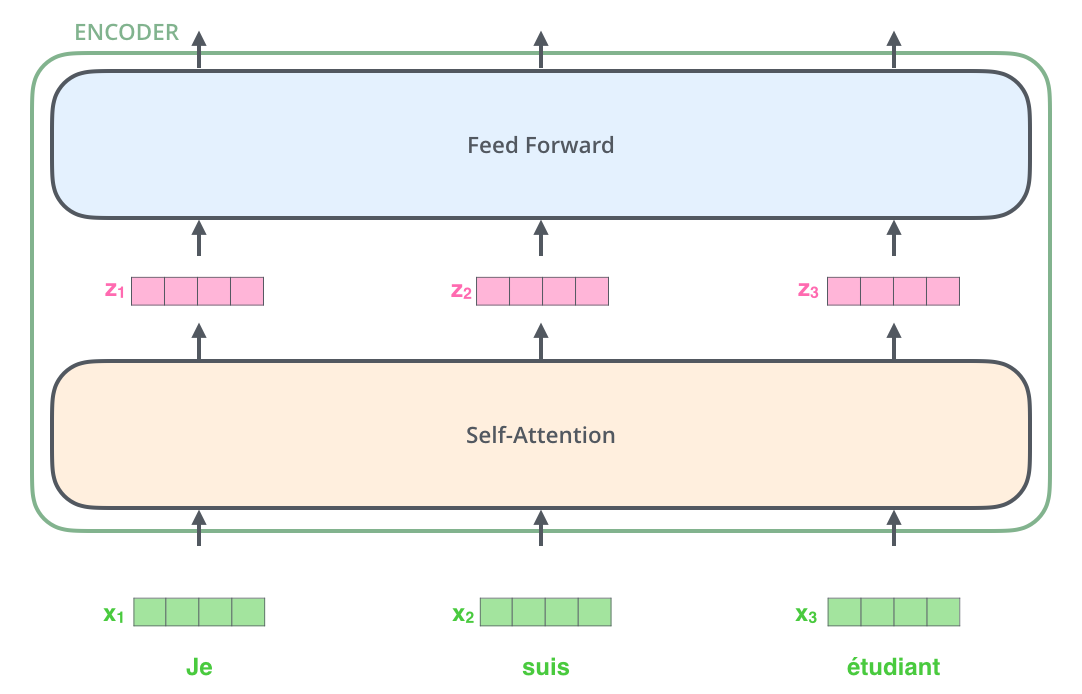

Главное, что нужно помнить при определении этой модели, - это передать информацию о количестве имеющихся у нас меток. Проще всего передать это число с помощью аргумента `num_labels`, но если мы хотим получить красивый виджет инференса на страничке нашей модели в HF, то лучше задать правильное сопоставление меток.

Оно должно задаваться двумя словарями, `id2label` и `label2id`, которые содержат соответствие между идентификатором и меткой и наоборот:


In [37]:
id2label = {i: label for i, label in enumerate(label_names)}
label2id = {v: k for k, v in id2label.items()}

Теперь мы можем просто передать их в метод `AutoModelForTokenClassification.from_pretrained()`, и они будут заданы в конфигурации модели, а затем правильно сохранены и загружены в Hub:

In [38]:
from transformers import AutoModelForTokenClassification
import torch

model = AutoModelForTokenClassification.from_pretrained(
    model_checkpoint,
    id2label=id2label,
    label2id=label2id,
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  714MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can 

Во время определения `AutoModelForSequenceClassification`, при создании модели выдается предупреждение о том, что некоторые веса не были использованы (те, что были получены из предварительно обученной головы), а другие инициализированы случайно (те, что были получены из новой головы классификации токенов), и что эту модель необходимо обучить. Мы сделаем это через минуту, но сначала давайте перепроверим, что наша модель имеет правильное количество меток:

In [39]:
model.config.num_labels

7

In [40]:
model.config.id2label

{0: 'O',
 1: 'B-PER',
 2: 'I-PER',
 3: 'B-ORG',
 4: 'I-ORG',
 5: 'B-LOC',
 6: 'I-LOC'}

#### 3.4. Дообучение модели

Теперь мы готовы к обучению нашей модели! Нам осталось сделать две последние вещи, прежде чем мы определим наш `Trainer`: войти в Hugging Face и Wandb и определить наши аргументы для обучения. Если вы работаете в блокноте, есть удобная функция, которая поможет вам в этом:

In [41]:
from huggingface_hub import notebook_login

notebook_login()

In [43]:
# ! pip install wandb -q

# import wandb
# wandb.login()

In [ ]:
import os
os.environ["WANDB_PROJECT"] = "rubert-finetuned-ner"

Определяем [`TrainingArguments`](https://huggingface.co/docs/transformers/en/main_classes/trainer#transformers.TrainingArguments):

In [47]:
from transformers import TrainingArguments

args = TrainingArguments(
    "rubert-finetuned-ner",
    eval_strategy="steps",
    eval_steps=0.25,
    save_strategy="epoch",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=1e-4,
    num_train_epochs=2,
    weight_decay=0.01,
    warmup_steps=0.1,
    lr_scheduler_type="cosine",
    logging_steps=1,
    push_to_hub=True,
    # report_to='wandb',
)

С большинством из них вы знакомы: мы задаем некоторые гиперпараметры (например, лернинг рейт, количество эпох для обучения и затухание весов) и указываем `push_to_hub=True`, чтобы указать, что мы хотим сохранить модель и оценить ее в конце каждой эпохи, а также что мы хотим загрузить наши результаты в Model Hub. Обратите внимание, что с помощью аргумента `hub_model_id` можно указать имя репозитория, в который вы хотите передать модель (в частности, этот аргумент нужно использовать, чтобы передать модель в организацию). По умолчанию используемый репозиторий будет находиться в вашем пространстве имен и называться в соответствии с заданным вами выходным каталогом.

In [49]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=tokenizer
)
trainer.train()
# wandb.finish()

Step,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
625,0.048078,0.234844,0.831782,0.854711,0.843090,0.939043
1250,0.348906,0.191895,0.853563,0.883736,0.868388,0.947874
1875,0.109356,0.172678,0.882190,0.901573,0.891776,0.956704
2500,0.054523,0.155860,0.887346,0.906843,0.896989,0.958005


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2500, training_loss=0.21114805079009383, metrics={'train_runtime': 448.6716, 'train_samples_per_second': 89.152, 'train_steps_per_second': 5.572, 'total_flos': 528300598518528.0, 'train_loss': 0.21114805079009383, 'epoch': 2.0})

Обратите внимание, что во время обучения каждый раз, когда модель сохраняется (здесь - каждую эпоху), она загружается в Hub в фоновом режиме. Таким образом, при необходимости вы сможете возобновить обучение на другой машине.

После завершения обучения мы используем метод `push_to_hub()`, чтобы убедиться, что загружена самая последняя версия модели:

In [ ]:
trainer.push_to_hub(commit_message="Training complete")

CommitInfo(commit_url='https://huggingface.co/evgsumina/rubert-finetuned-ner/commit/774fcd1a99cae3ddea165ade319a9fba285929b7', commit_message='Training complete', commit_description='', oid='774fcd1a99cae3ddea165ade319a9fba285929b7', pr_url=None, pr_revision=None, pr_num=None)

Trainer также создает черновик карточки модели со всеми результатами оценки и загружает его. Вы успешно дообучили модель для задачи классификации токенов - поздравляем!

### 4. Использование дообученной модели

In [ ]:
from transformers import pipeline

# Replace this with your own checkpoint
model_checkpoint = "evgsumina/rubert-finetuned-ner"
token_classifier = pipeline(
    "token-classification", model=model_checkpoint, aggregation_strategy="simple"
)

config.json:   0%|          | 0.00/1.14k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/709M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.57M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Hardware accelerator e.g. GPU is available in the environment, but no `device` argument is passed to the `Pipeline` object. Model will be on CPU.


In [ ]:
sentence = "Иван Иванович Иванов родился в Ставрополе и работает землекопом в ОАО РедПис."

In [ ]:
token_classifier(sentence)

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


[{'entity_group': 'PER',
  'score': 0.9805487,
  'word': 'Иван Иванович Иванов',
  'start': 0,
  'end': 20},
 {'entity_group': 'LOC',
  'score': 0.9946965,
  'word': 'Ставрополе',
  'start': 31,
  'end': 41},
 {'entity_group': 'ORG',
  'score': 0.81021017,
  'word': 'ОАО РедПис',
  'start': 66,
  'end': 76}]